# Restoring Historical Photographs with Fine-Tuned Generative AI Models
## Notebook 1 — Problem Definition, Data Acquisition, EDA and Pre-processing

**AAI-521 Final Team Project (extra-credit track), Group 3:** Nolan Robbins · Sean McGowan · Jackson Kenyon

| Notebook | Contents |
|---|---|
| **01_data_and_eda** (this) | Problem definition, datasets, EDA, curation, leakage-safe splits, degradation pipeline |
| 02_finetuning | Fine-tuning the four pretrained Hugging Face models |
| 03_evaluation | Baselines vs. zero-shot vs. fine-tuned on the held-out test set |
| 04_web_app | Flask application chaining the four tasks |

## Environment setup

Runs unchanged on **Google Colab** or locally.

* **Colab:** clones the repo, installs it, mounts Google Drive and copies the packed
  dataset (`MyDrive/aai521/aai521_dataset.tar`, made by `scripts/pack_dataset.py`) to the
  VM's fast local disk. Checkpoints are written to `MyDrive/aai521/checkpoints`, so they
  survive disconnects.
* **Locally:** uses `$AAI521_DATA_ROOT` from `.env`.

All project logic lives in the importable `restoration` package (`src/restoration`), so
the notebooks stay focused on the narrative, results and figures.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git clone -q https://github.com/NolanRobbins/AAI-521-Final-Project.git /content/AAI-521-Final-Project 2>/dev/null || git -C /content/AAI-521-Final-Project pull -q
    %cd /content/AAI-521-Final-Project
    !pip install -q -r requirements.txt && pip install -q -e .
    sys.path.insert(0, "/content/AAI-521-Final-Project/src")  # editable install, no restart needed

from restoration import colab

paths = colab.setup()  # must run before importing model code (sets HF_HOME on Colab)
paths

{'data_root': 'C:\\Users\\Robbinhood\\aai521_data',
 'checkpoint_root': 'C:\\Users\\Robbinhood\\aai521_data\\checkpoints'}

In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from restoration.config import load_data_config, processed_dir, raw_dir
from restoration.data import degradations as deg, quality
from restoration.data.records import load_manifest
from restoration.evaluation.plotting import (
    SOURCE_COLORS, SOURCE_LABELS, apply_style, image_grid,
)

apply_style()
cfg = load_data_config()
rng = np.random.default_rng(cfg.seed)
pd.set_option("display.max_colwidth", 60)

## 1. Problem definition

**What problem are we solving?** Archives and families hold millions of deteriorating
photographs. Film grain and scan noise, scratches, cracks and stains, missing colour
(black-and-white originals or faded dyes) and low digitisation resolution all degrade
them. Manual restoration in Photoshop takes an expert minutes to hours per image.

**Why does it need to be solved?** Collections such as the Library of Congress FSA/OWI
archive (~175,000 negatives) are far too large to restore by hand. General-purpose
models trained on modern digital photos do not handle film grain, fading or physical
damage well, so restoration models need adapting to *period* imagery.

**What does computer vision solve?** We chain four image-to-image models, each a
pretrained Hugging Face checkpoint fine-tuned on 1930s–1970s photographs paired with
synthetically damaged copies:

| Step | Task | Input → Output | Model |
|---|---|---|---|
| 1 | Denoising | grainy/noisy → clean | SCUNet |
| 2 | Inpainting | scratched/torn + mask → filled | Stable Diffusion 1.5 Inpainting + LoRA |
| 3 | Colorization | greyscale → colour | DDColor |
| 4 | Super-resolution | low-res → 4× high-res | Swin2SR |

The order matters. Noise would be hallucinated into texture by the later generative
steps, and colour should be predicted before upsampling (DDColor predicts only chroma
at 512 px and reuses the full-resolution lightness).

## 2. Data acquisition

All sources are public. `scripts/download_data.py` downloads them with rate limiting,
resumes after interruptions, verifies every file decodes, and writes one
`manifest.csv` per source.

| Source | Role | Notes |
|---|---|---|
| LoC **FSA/OWI Color Photographs** 1939–44 | train / val / test | Kodachrome slides scanned to TIFF masters; fetched as full-res IIIF renders, area-downscaled to 2048 px |
| **DOCUMERICA** (EPA) 1972–77 | train / val / test | NARA scans mirrored on Wikimedia Commons; 6,400 sampled from 15,887 unique photos |
| LoC **FSA/OWI B&W negatives** | real-damage test (no ground truth) | 300-image candidate pool sampled across the 171k collection |
| **NVIDIA Irregular Masks** (Liu et al., 2018) | inpainting masks | 12,000 masks in six hole-ratio bins |
| **DIV2K** validation HR | modern-photo sanity check | 100 images, the NTIRE standard |
| **RealOld** (Pik-Fix, WACV 2023) | real damage + expert ground truth | available from the authors on request |

In [3]:
sources = ["loc_fsa_color", "documerica", "loc_fsa_bw", "div2k_valid"]
manifests = {s: load_manifest(raw_dir(s)) for s in sources}
masks = pd.read_csv(raw_dir("nvidia_masks") / "manifest.csv")
curated = pd.read_csv(processed_dir() / "curated.csv", keep_default_na=False)
splits = pd.read_csv(processed_dir() / "splits.csv", keep_default_na=False)

overview = pd.DataFrame(
    {
        "images": [len(manifests[s]) for s in sources] + [len(masks)],
        "median width": [int(manifests[s]["width"].median()) for s in sources] + [512],
        "median height": [int(manifests[s]["height"].median()) for s in sources] + [512],
        "kept after curation": [int(curated.query("source == @s")["keep"].sum()) if s in curated["source"].unique() else "-" for s in sources] + ["-"],
    },
    index=[SOURCE_LABELS[s] for s in sources] + ["NVIDIA irregular masks"],
)
size_gb = sum(f.stat().st_size for s in sources for f in (raw_dir(s) / "images").glob("*") if f.is_file()) / 2**30
print(f"Image data on disk: {size_gb:.1f} GB")
overview

Image data on disk: 4.7 GB


,images,median width,median height,kept after curation
FSA/OWI colour (1939-44),1615,2048,1601,1427
DOCUMERICA (1972-77),6400,1920,1303,5736
FSA/OWI B&W negatives,300,2048,1459,-
DIV2K (modern),100,2040,1356,-
NVIDIA irregular masks,12000,512,512,-


### Sample images

Top two rows are training sources (clean ground truth). The bottom row shows real damage
from the B&W negatives: emulsion cracks, scratches, dust, fading, and even **hole
punches**. The FSA project physically punched the negatives it rejected ("killed"
negatives), which gives us genuine large-hole inpainting cases. Our synthetic
degradations imitate this damage.

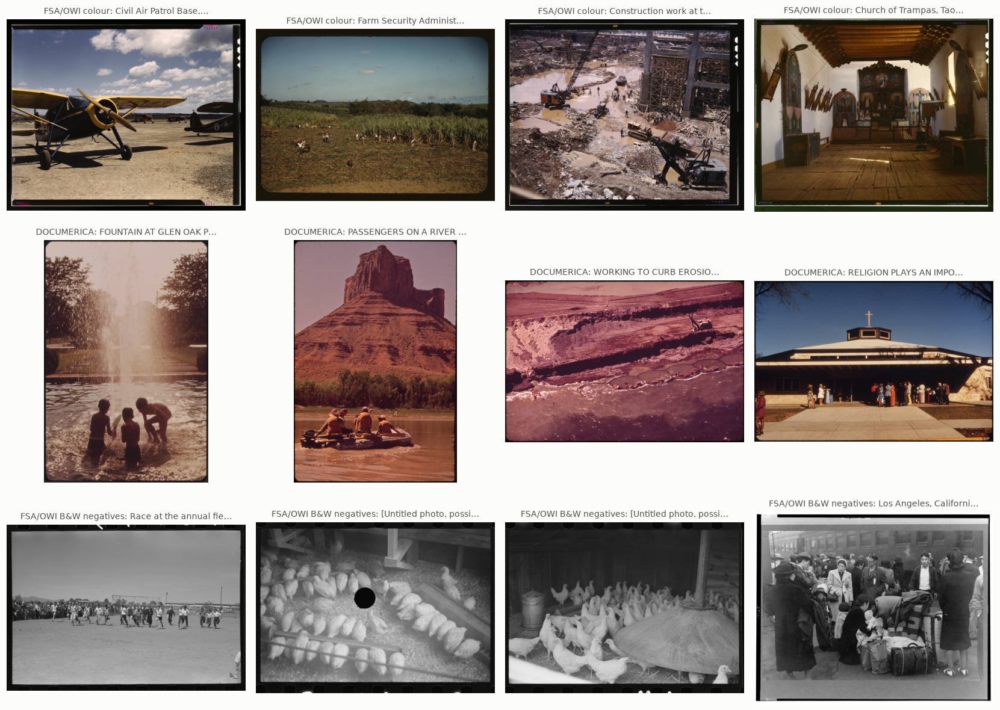

In [4]:
def load(path, max_side=768):
    return deg.resize_max_side(deg.to_float(np.asarray(Image.open(path).convert("RGB"))), max_side)

picks, titles = [], []
for s in ["loc_fsa_color", "documerica", "loc_fsa_bw"]:
    m = manifests[s].sample(4, random_state=cfg.seed)
    picks += [load(raw_dir(s) / p) for p in m["path"]]
    titles += [f"{SOURCE_LABELS[s].split(' (')[0]}: {t[:22]}…" for t in m["title"]]
image_grid(picks, titles, ncols=4, size=3.8);

## 3. Exploratory data analysis

We need to know whether the scans are good enough to serve as ground truth, and how the
archives differ. Scale-dependent features are measured at a common 1024 px analysis
size (`restoration.data.quality`):

* **Sharpness**: variance of the Laplacian (focus measure).
* **Noise σ**: Immerkær's fast estimator (Laplacian-difference kernel cancels structure).
* **Colourfulness**: Hasler & Süsstrunk (2003), on a 0–255 scale.
* **Borders**: uniform dark rows/columns from slide mounts and film edges.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


,sharpness,noise_sigma,colorfulness
source,,,
DIV2K (modern),0.0161,0.0108,42.6786
DOCUMERICA (1972-77),0.0022,0.0028,34.3732
FSA/OWI colour (1939-44),0.0061,0.0043,26.5229


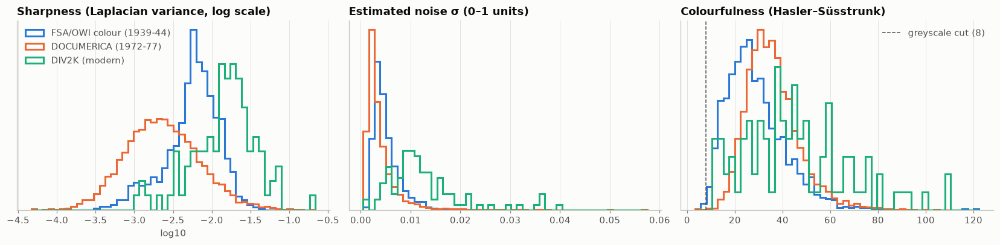

In [5]:
# DIV2K is a modern reference for colourfulness / sharpness.
div2k_feats = pd.DataFrame(
    [quality.compute_features(load(raw_dir("div2k_valid") / p, 2048)).as_dict() for p in manifests["div2k_valid"]["path"]]
).assign(source="div2k_valid")
feats = pd.concat([curated, div2k_feats], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
specs = [
    ("sharpness", "Sharpness (Laplacian variance, log scale)", True),
    ("noise_sigma", "Estimated noise σ (0–1 units)", False),
    ("colorfulness", "Colourfulness (Hasler–Süsstrunk)", False),
]
for ax, (col, title, logx) in zip(axes, specs):
    values = np.log10(feats[col].clip(lower=1e-6)) if logx else feats[col]
    bins = np.histogram_bin_edges(values, bins=50)
    for s in ["loc_fsa_color", "documerica", "div2k_valid"]:
        v = values[feats["source"] == s]
        ax.hist(v, bins=bins, density=True, histtype="step", linewidth=2, color=SOURCE_COLORS[s], label=SOURCE_LABELS[s])
    ax.set_title(title, loc="left")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    if logx:
        ax.set_xlabel("log10")
axes[2].axvline(cfg.curation.min_colorfulness, color="#52514e", linestyle="--", linewidth=1,
                label=f"greyscale cut ({cfg.curation.min_colorfulness:g})")
axes[2].legend(handles=[axes[2].lines[-1]], loc="upper right")
axes[0].legend(loc="upper left")
fig.tight_layout()

feats.groupby("source")[["sharpness", "noise_sigma", "colorfulness"]].median().rename(index=SOURCE_LABELS).round(4)

**Findings.**

* **Colourfulness:** FSA/OWI (median ≈ 27) < DOCUMERICA (≈ 34) < modern DIV2K (≈ 43).
  Both archives are **dye-faded**: the 1940s Kodachromes are warm and desaturated, and
  many 1970s Ektachromes carry a magenta cast from cyan-dye loss (visible in the sample
  grid). Their "ground-truth" colours are therefore period-faithful *but faded*. Section 3b
  shows how we handle this for colorization.
* **Sharpness:** DOCUMERICA scans are the softest (median Laplacian variance about ⅓ of
  FSA/OWI's), consistent with lower-resolution NARA digitisation. DIV2K is sharpest.
* **Noise:** the estimated σ is *highest for DIV2K*. No-reference noise estimators also
  respond to genuine fine texture, so absolute thresholds would be misleading. Hence
  curation uses **per-source percentiles**: each archive is judged against its own
  scanning pipeline.

### 3b. Dye fading and colorization targets

If we fine-tuned DDColor on faded targets, it would learn to paint black-and-white photos
with the same sepia and magenta casts. For the colorization targets only, we therefore
partially undo fading in CIELAB (`degradations.correct_fading`):

1. stretch L between its 1st and 99th percentiles (restores lost contrast);
2. remove 70 % of the median a/b cast (a tempered grey-world, so scenes that genuinely
   are one colour keep most of it);
3. boost chroma by 15 %.

This is a trade-off, and we evaluate it as an ablation (colorization with vs. without
target correction) in notebook 03.

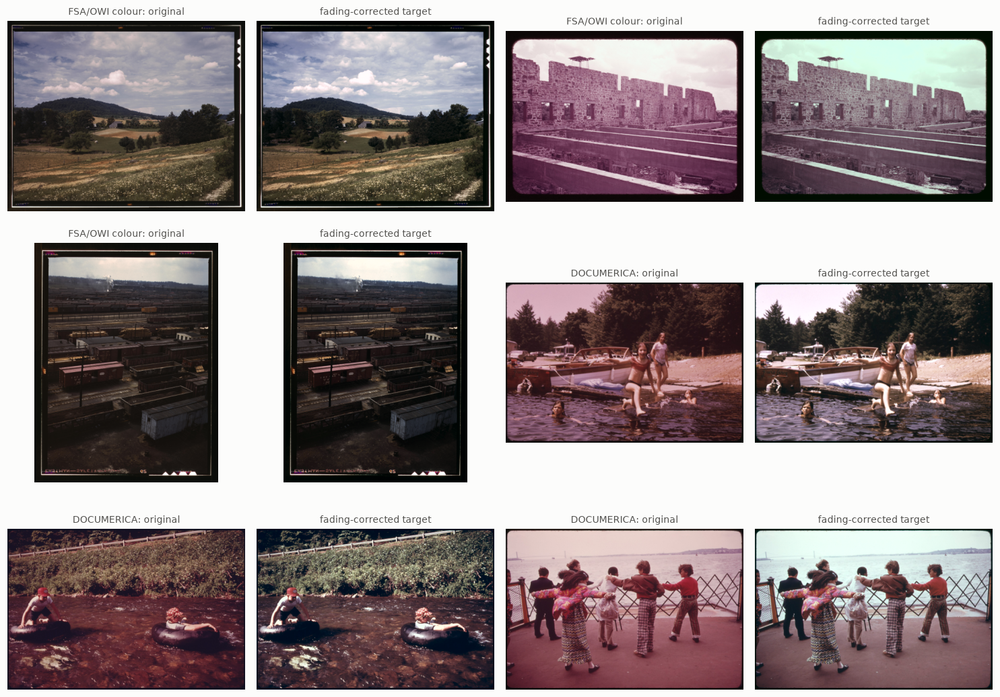

In [6]:
examples, captions = [], []
for s in ["loc_fsa_color", "documerica"]:
    m = splits[splits["source"] == s].sample(3, random_state=7)
    for r in m.itertuples():
        img = load(raw_dir(s) / r.path, 512)
        examples += [img, deg.correct_fading(img)]
        captions += [f"{SOURCE_LABELS[s].split(' (')[0]}: original", "fading-corrected target"]
image_grid(examples, captions, ncols=4, size=3.4);

### Lab colour space: the colorization features

Colorization is posed in CIELAB. The **L** (lightness) channel is the model input and
the two chroma channels **a** (green–red) and **b** (blue–yellow) are the targets. The
image's structure lives almost entirely in L, which is why predicting only *ab* preserves
detail.

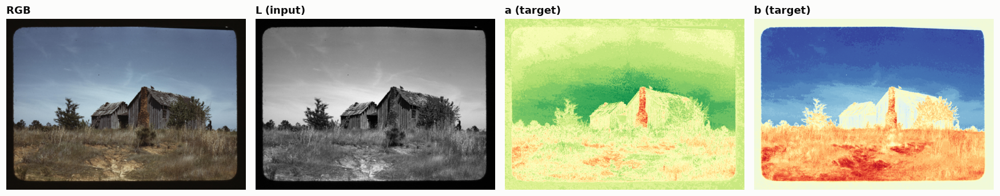

In [7]:
sample = load(raw_dir("loc_fsa_color") / manifests["loc_fsa_color"]["path"].iloc[7], 640)
lab = cv2.cvtColor(sample, cv2.COLOR_RGB2LAB)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
panels = [(sample, "RGB", None), (lab[..., 0], "L (input)", "gray"), (lab[..., 1], "a (target)", "RdYlGn_r"), (lab[..., 2], "b (target)", "RdYlBu_r")]
for ax, (img, title, cmap) in zip(axes, panels):
    ax.imshow(img, cmap=cmap) if cmap else ax.imshow(img)
    ax.set_title(title, loc="left"); ax.axis("off")
fig.tight_layout()

## 4. Bad data and curation

The status update form anticipated three problems: unreliable ground truth (dust,
fading, blur), film borders and mounts, and near-duplicate frames. `scripts/curate_and_split.py`
handles each of them with rules from `configs/data.yaml`, applied in order (first failing rule wins):

| Rule | Threshold |
|---|---|
| too small | shortest side < 1024 px |
| borders | detected mount/edge > 45 % of a side |
| near-greyscale | colourfulness < 8 (colour sources only) |
| blurry | bottom 5 % sharpness *per source* |
| noisy | top 5 % noise σ *per source* |

Borders below the threshold are not discarded. Their boxes are stored and trimmed when
the training patches are drawn.

**EDA-driven revision.** Our first pass dropped any image whose borders exceeded 25 % of a
side, which removed 385 images. Inspecting them showed the detector also fires on
**dark, low-key scenes** (night shots, deep shadows): their rows are dark and uniform,
just like a mount. Dropping them would bias training toward bright daylight scenes.
Because borders are cropped anyway, we raised the drop threshold to 45 %. That recovered
360 images. The 25 still removed for "borders" are frames where border-like rows and
columns cover nearly half the image: mostly extreme low-key scenes that are poor
targets anyway, as in the example below.

In [8]:
summary = (
    curated.assign(reason=curated["drop_reason"].replace("", "kept"))
    .groupby(["source", "reason"]).size().unstack(fill_value=0)
    .rename(index=SOURCE_LABELS)
)
summary = summary[["kept"] + [c for c in summary.columns if c != "kept"]]
summary

reason,kept,blurry,borders,near_greyscale,noisy,too_small
source,,,,,,
DOCUMERICA (1972-77),5736,307,25,4,319,9
FSA/OWI colour (1939-44),1427,81,0,6,74,27


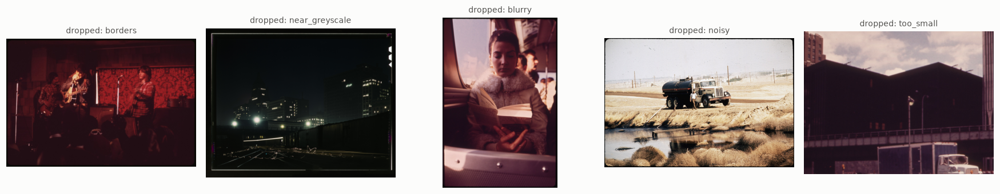

In [9]:
examples, captions = [], []
for reason in ["borders", "near_greyscale", "blurry", "noisy", "too_small"]:
    row = curated[curated["drop_reason"] == reason].sample(1, random_state=1).iloc[0]
    examples.append(load(raw_dir(row["source"]) / row["path"], 512))
    captions.append(f"dropped: {reason}")
image_grid(examples, captions, ncols=5, size=3.2);

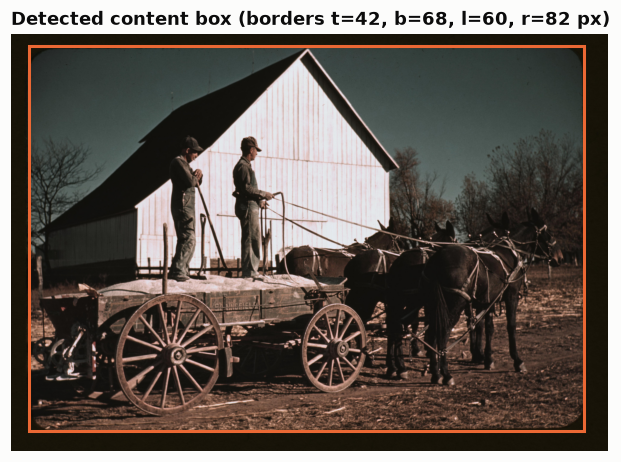

In [10]:
# Border detection on a slide with a visible mount
row = curated[(curated["source"] == "loc_fsa_color") & (curated["border_top"] > 20) & curated["keep"]].iloc[0]
img = load(raw_dir(row["source"]) / row["path"], 4096)
h, w = img.shape[:2]
t, b, l, r = (int(row[k]) for k in ["border_top", "border_bottom", "border_left", "border_right"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(img); ax.axis("off")
ax.add_patch(plt.Rectangle((l, t), w - l - r, h - t - b, fill=False, edgecolor="#eb6834", linewidth=2))
ax.set_title(f"Detected content box (borders t={t}, b={b}, l={l}, r={r} px)", loc="left");

## 5. Leakage-safe train / validation / test splits

Archive photographers shot several frames of the same scene. If one frame lands in
train and its twin in test, the test score is inflated. We link two images when
**any** of these holds:

1. their 64-bit perceptual hashes (pHash) differ by ≤ 8 bits;
2. they share a normalised caption within the same source;
3. they share an archive identifier.

Each **connected component** of these links goes into exactly one split (80/10/10).

In [11]:
split_table = splits.groupby(["source", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
split_table.loc["total"] = split_table.sum()
group_sizes = splits.groupby("group").size()
print(f"{len(splits):,} images in {group_sizes.size:,} groups; "
      f"{(group_sizes > 1).sum():,} multi-image groups; largest = {group_sizes.max()}")
split_table.rename(index=SOURCE_LABELS)

7,163 images in 6,274 groups; 554 multi-image groups; largest = 13


split,train,val,test
source,,,
DOCUMERICA (1972-77),4576,561,599
FSA/OWI colour (1939-44),1155,155,117
total,5731,716,716


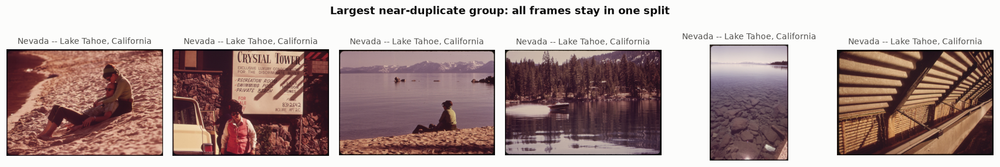

In [12]:
largest = group_sizes.sort_values(ascending=False).index[0]
members = splits[splits["group"] == largest].head(6)
image_grid([load(raw_dir(r.source) / r.path, 400) for r in members.itertuples()],
           [r.title[:40] for r in members.itertuples()], ncols=6, size=2.6,
           suptitle="Largest near-duplicate group: all frames stay in one split");

## 6. Pre-processing: synthesising degraded / clean training pairs

Old photos with *known* clean versions barely exist, so we generate inputs from clean
scans (`restoration.data.degradations`). A fresh random degradation is drawn **every
time an image is loaded**, which acts as unlimited augmentation. Validation and test
pairs are seeded by image index, so they are fixed and reproducible.

| Task | Degradation (inputs) | Target |
|---|---|---|
| Denoise | luminance-dependent, spatially correlated **film grain** + Gaussian σ ∈ [2, 30]/255 + JPEG (q 50–95, p = 0.4) | clean patch |
| Super-res | Gaussian blur σ ∈ [0.2, 1.6] → **bicubic ×4 downsample** → noise → JPEG | HR patch |
| Colorize | CIELAB **L channel only** (grey RGB) | colour image |
| Inpaint | procedural **scratches / branching cracks / blotches** or **NVIDIA irregular masks**, filled like scan damage | clean patch + mask |

Training patches are random 256–512 px crops at random scales (0.5–1×), with
flips/rotations for every task except colorization, which only uses horizontal flips
so the sky stays up.

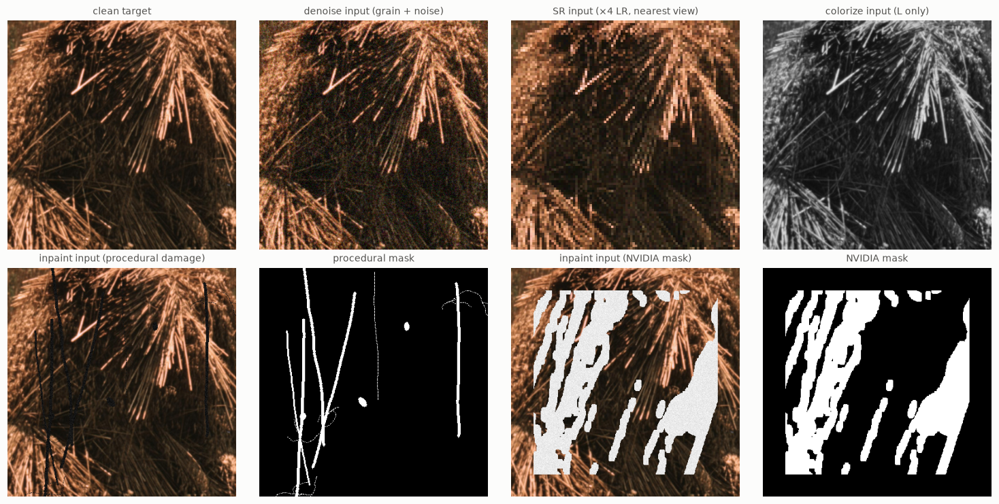

In [13]:
row = splits[splits["source"] == "loc_fsa_color"].iloc[3]
clean = deg.random_crop(load(raw_dir(row["source"]) / row["path"], 2048), 384, np.random.default_rng(3))
r = np.random.default_rng(0)
noisy = deg.make_denoise_pair(clean, r).inp
lr = deg.make_sr_pair(clean, r).inp
lr_up = cv2.resize(lr, clean.shape[1::-1], interpolation=cv2.INTER_NEAREST)
grey = deg.make_colorization_pair(clean).inp
damaged = deg.make_inpaint_pair(clean, r)
nv_mask = np.asarray(Image.open(raw_dir("nvidia_masks") / masks["path"].iloc[4321]).convert("L")) < 128
nv_mask = ~nv_mask if nv_mask.mean() > 0.5 else nv_mask  # holes are the minority value
nv = deg.make_inpaint_pair(clean, r, external_mask=nv_mask)
image_grid(
    [clean, noisy, lr_up, grey, damaged.inp, damaged.mask.astype(float), nv.inp, nv.mask.astype(float)],
    ["clean target", "denoise input (grain + noise)", "SR input (×4 LR, nearest view)", "colorize input (L only)",
     "inpaint input (procedural damage)", "procedural mask", "inpaint input (NVIDIA mask)", "NVIDIA mask"],
    ncols=4, size=3.4,
);

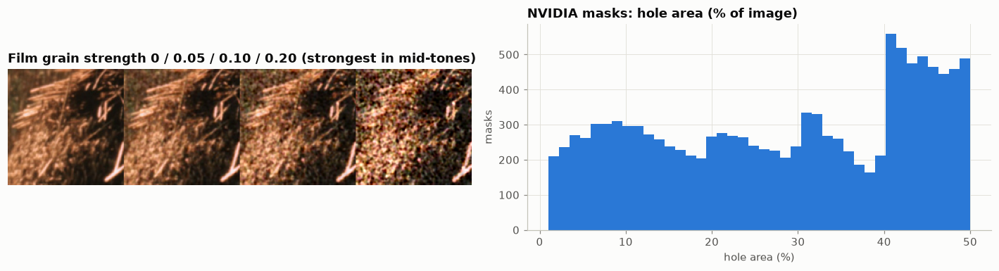

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
strengths = [0.0, 0.05, 0.10, 0.20]
patch = clean[:128, :128]
axes[0].imshow(np.concatenate([deg.add_film_grain(patch, s, 1.0, np.random.default_rng(0)) for s in strengths], axis=1))
axes[0].set_title("Film grain strength 0 / 0.05 / 0.10 / 0.20 (strongest in mid-tones)", loc="left"); axes[0].axis("off")
axes[1].hist(masks["hole_ratio"] * 100, bins=40, color=SOURCE_COLORS["loc_fsa_color"])
axes[1].set_title("NVIDIA masks: hole area (% of image)", loc="left")
axes[1].set_xlabel("hole area (%)"); axes[1].set_ylabel("masks")
fig.tight_layout()

## 7. Are we ready for deep learning?

* **Data volume:** 7,163 curated colour photographs (5,731 train / 716 val / 716 test),
  plus 12,000 masks. Random crops and per-load degradation give effectively unlimited
  distinct training pairs.
* **Data quality:** every image decodes, is at least 1024 px on its shortest side, and
  passed sharpness/noise/border/colour checks. Borders are trimmed at load time.
* **No leakage:** near-duplicate groups are confined to one split. The real-damage B&W
  pool, DIV2K and RealOld are used only for evaluation.
* **Feature definition:** inputs and targets for each task are explicit (table in §6).
  Colorization uses Lab L → ab. The pretrained encoders inside each Hugging Face model
  do the feature learning, and fine-tuning adapts them to period damage.
* **Image access for AI computation:** `restoration.training.datasets.RestorationPairs`
  serves CHW float tensors to PyTorch `DataLoader`s. `scripts/pack_dataset.py` packs the
  curated set into one archive that Colab stages onto local disk.

**Next:** `02_finetuning.ipynb`.